In [ ]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

# Step 2: Load the company-provided dataset

import pandas as pd
import numpy as np

df = pd.read_csv('/content/housing.txt')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (20640, 10)

First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values in each column:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


## 3. Exploratory Data Analysis (EDA)

In this section, we examine the dataset's structure, statistical properties, missing values, duplicate records, target variable distribution, and relationships between features. This analysis helps us identify data quality issues and make informed preprocessing decisions before model training.

In [ ]:

# Step 3.2: Summary statistics and duplicate analysis

print("Summary statistics:")
display(df.describe().T)

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nDataset dimensions:", df.shape)

print("\nUnique values in ocean_proximity:")
print(df["ocean_proximity"].value_counts())


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000



Number of duplicate rows: 0

Dataset dimensions: (20640, 10)

Unique values in ocean_proximity:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


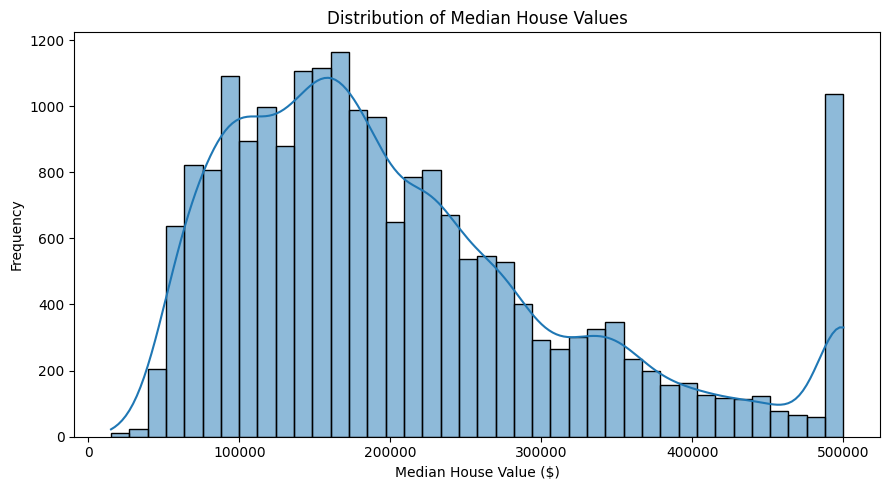

In [ ]:

# Step 3.3: Distribution of median house values

plt.figure(figsize=(9, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


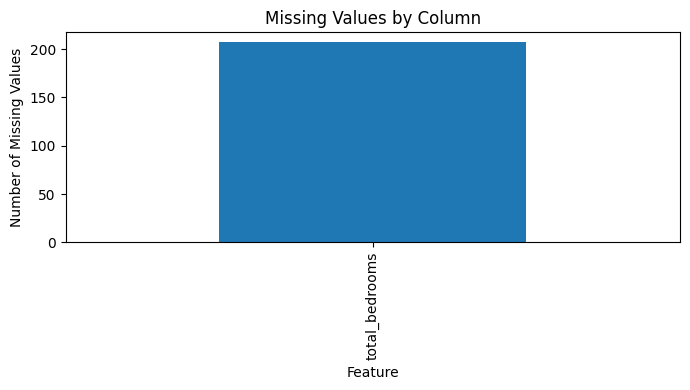

In [ ]:

# Step 3.4: Missing-value analysis

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(7, 4))
    plt.title("Missing Values by Column")
    plt.ylabel("Number of Missing Values")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


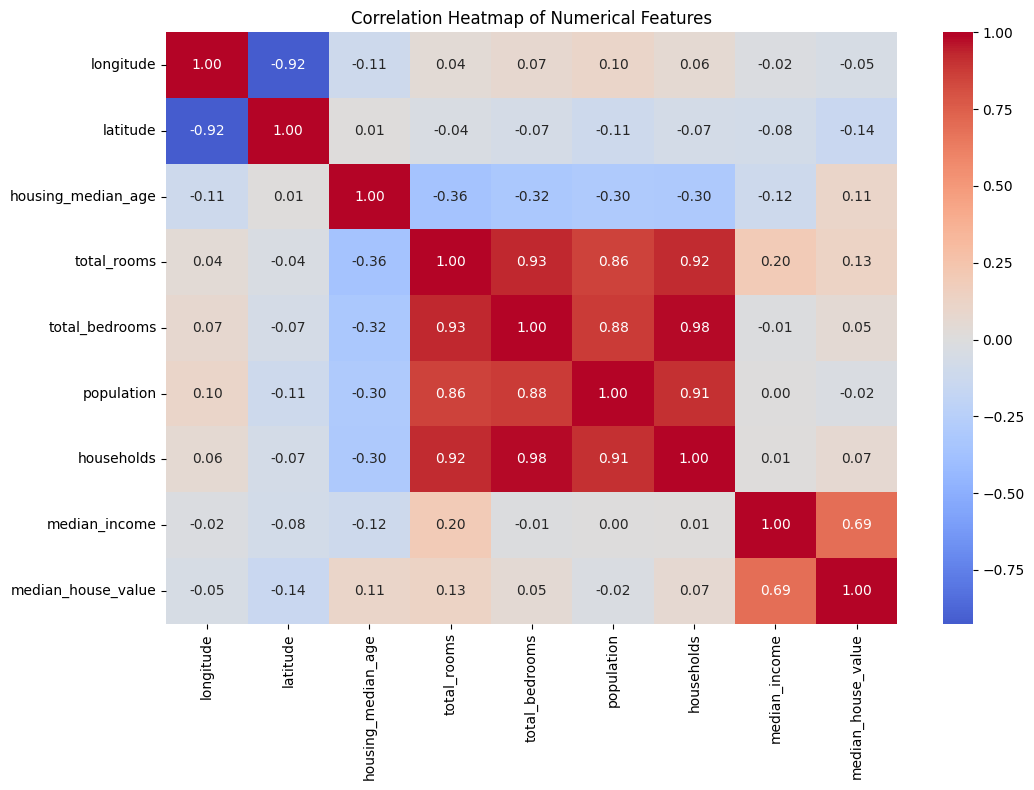

In [ ]:

# Step 3.5: Correlation heatmap for numerical features

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


## 4. Feature Engineering and Train-Test Split

Feature engineering creates useful variables from existing data. For this housing dataset, we will calculate rooms per household, bedrooms per room, and population per household. These ratios provide more meaningful neighborhood-level information than raw counts alone.

We will then split the data into training and testing sets. The training set will be used to fit models, while the test set will be reserved for final evaluation.

In [ ]:

# Step 4.2: Feature engineering

df_model = df.copy()

# Useful neighborhood-level ratios
df_model["rooms_per_household"] = (
    df_model["total_rooms"] / df_model["households"]
)

df_model["bedrooms_per_room"] = (
    df_model["total_bedrooms"] / df_model["total_rooms"]
)

df_model["population_per_household"] = (
    df_model["population"] / df_model["households"]
)

# Interaction feature: income multiplied by house age
df_model["income_x_house_age"] = (
    df_model["median_income"] * df_model["housing_median_age"]
)

print("New features created successfully!")

display(
    df_model[
        [
            "median_income",
            "housing_median_age",
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household",
            "income_x_house_age"
        ]
    ].head()
)

print("\nMissing values in engineered features:")
display(df_model[
    [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household",
        "income_x_house_age"
    ]
].isnull().sum())


New features created successfully!


,median_income,housing_median_age,rooms_per_household,bedrooms_per_room,population_per_household,income_x_house_age
0,8.3252,41.0,6.984127,0.146591,2.555556,341.3332
1,8.3014,21.0,6.238137,0.155797,2.109842,174.3294
2,7.2574,52.0,8.288136,0.129516,2.802260,377.3848
3,5.6431,52.0,5.817352,0.184458,2.547945,293.4412
4,3.8462,52.0,6.281853,0.172096,2.181467,200.0024



Missing values in engineered features:


,0
rooms_per_household,0
bedrooms_per_room,207
population_per_household,0
income_x_house_age,0


In [ ]:

# Step 4.3: Separate features and target

from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["median_house_value"])
y = df_model["median_house_value"]

# 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 13)
Testing features: (4128, 13)
Training target: (16512,)
Testing target: (4128,)


## 5. Data Preprocessing

The dataset contains numerical features and one categorical feature, ocean_proximity. We will use median imputation for missing numerical values, standardization for numerical features, and one-hot encoding for categorical features.

All transformations will be fitted using training data only through a Scikit-learn Pipeline and ColumnTransformer. This prevents data leakage and ensures consistent preprocessing during cross-validation and testing.

In [ ]:

# Step 5.2: Build the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing: impute missing values and scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: impute and one-hot encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_house_age']

Categorical features: ['ocean_proximity']

Preprocessing pipeline created successfully!


In [ ]:

# Step 5.3: Fit preprocessing on training data only

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values remaining in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values remaining in testing data:",
      np.isnan(X_test_processed).sum())


Processed training shape: (16512, 17)
Processed testing shape: (4128, 17)

Missing values remaining in training data: 0
Missing values remaining in testing data: 0


## 6. Model Training and Baseline Evaluation

We train three regression models: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression. Each model uses the same preprocessing pipeline and training data to ensure a fair comparison. We evaluate their initial performance on the held-out test dataset using RMSE, MAE, and R².

In [ ]:

# Step 6.3: Train baseline regression models

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

# Define the models
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=20000)
}

# Train and evaluate each model
baseline_results = []
baseline_predictions = {}

for name, model in models.items():
    # Each model gets its own preprocessing pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Fit using training data
    pipeline.fit(X_train, y_train)

    # Predict on unseen test data
    y_pred = pipeline.predict(X_test)
    baseline_predictions[name] = y_pred

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    baseline_results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(f"{name} model trained successfully!")

# Display results
baseline_df = pd.DataFrame(baseline_results)
display(baseline_df.round(4))


OLS model trained successfully!
Ridge model trained successfully!
Lasso model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.084e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


,Model,RMSE,MAE,R2
0,OLS,69048.1923,49376.4886,0.6362
1,Ridge,69056.2204,49382.6281,0.6361
2,Lasso,69048.2041,49376.4991,0.6362


In [ ]:

# Step 6.3A: Improve Lasso convergence

lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=0.01, max_iter=100000, tol=1e-4))
])

lasso_pipeline.fit(X_train, y_train)

lasso_pred = lasso_pipeline.predict(X_test)

lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("Updated Lasso baseline:")
print(f"RMSE: ${lasso_rmse:,.2f}")
print(f"MAE:  ${lasso_mae:,.2f}")
print(f"R²:   {lasso_r2:.4f}")

# Update saved predictions and comparison results
baseline_predictions["Lasso"] = lasso_pred

baseline_df.loc[baseline_df["Model"] == "Lasso",
                ["RMSE", "MAE", "R2"]] = [
    lasso_rmse, lasso_mae, lasso_r2
]

display(baseline_df.round(4))


Updated Lasso baseline:
RMSE: $69,048.20
MAE:  $49,376.50
R²:   0.6362


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.084e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


,Model,RMSE,MAE,R2
0,OLS,69048.1923,49376.4886,0.6362
1,Ridge,69056.2204,49382.6281,0.6361
2,Lasso,69048.2041,49376.4991,0.6362


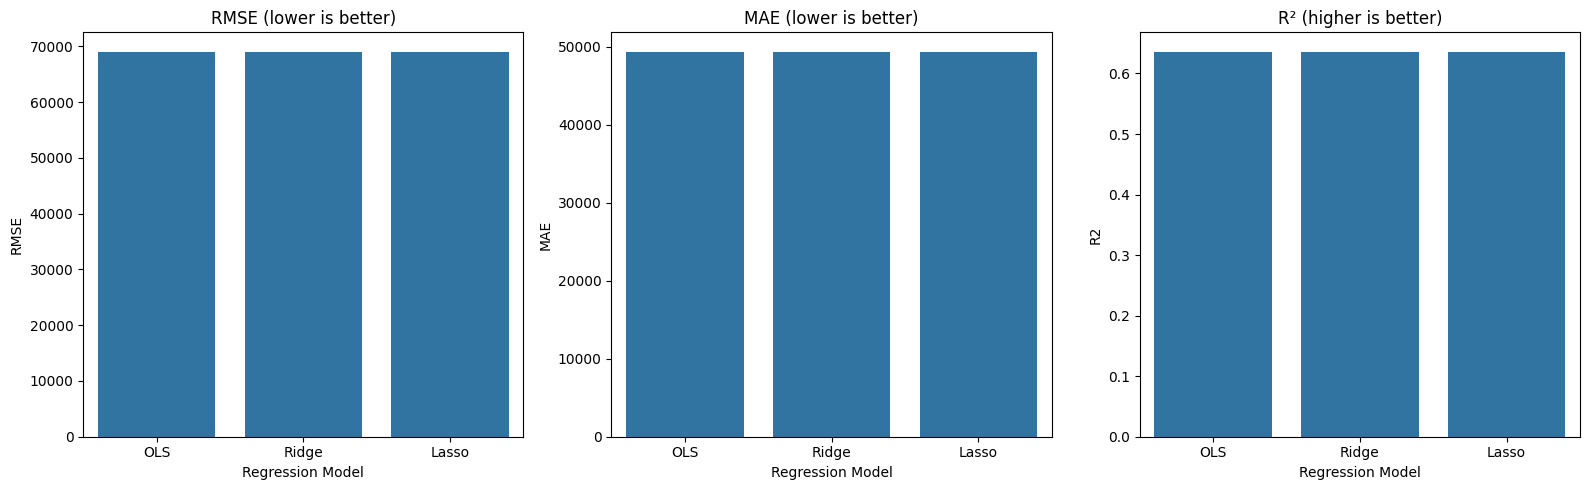

In [ ]:

# Step 6.4: Compare baseline model metrics

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("RMSE", "RMSE (lower is better)"),
    ("MAE", "MAE (lower is better)"),
    ("R2", "R² (higher is better)")
]

for ax, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=baseline_df,
        x="Model",
        y=metric,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Regression Model")
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()


## 7. Hyperparameter Tuning Using GridSearchCV

Ridge and Lasso regression use the regularization parameter alpha to control the strength of their coefficient penalties. We use GridSearchCV with five-fold cross-validation to identify suitable alpha values using training data only. The models are selected by minimizing cross-validated RMSE.

In [ ]:

# Step 7: Hyperparameter tuning for Ridge and Lasso

from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

tuned_models = {}
tuning_results = []

for name, estimator in [
    ("Ridge", Ridge()),
    ("Lasso", Lasso(max_iter=100000, tol=1e-4))
]:
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    param_grid = {
        "model__alpha": alpha_values
    }

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)
    tuned_models[name] = search

    tuning_results.append({
        "Model": name,
        "Best Alpha": search.best_params_["model__alpha"],
        "Best CV RMSE": -search.best_score_
    })

    print(f"\n{name} tuning completed.")
    print("Best parameters:", search.best_params_)
    print("Best cross-validation RMSE:", round(-search.best_score_, 2))

display(pd.DataFrame(tuning_results).round(4))



Ridge tuning completed.
Best parameters: {'model__alpha': 1}
Best cross-validation RMSE: 67728.46

Lasso tuning completed.
Best parameters: {'model__alpha': 100}
Best cross-validation RMSE: 67726.17


,Model,Best Alpha,Best CV RMSE
0,Ridge,1,67728.4566
1,Lasso,100,67726.1689


## 8. Final Model Evaluation

We evaluate the baseline OLS model and the tuned Ridge and Lasso models on the held-out test set using RMSE, MAE, and R². The test set is not used for hyperparameter selection, providing a fairer estimate of performance on unseen data.

In [ ]:

# Step 8.1: Final evaluation on the test set

final_predictions = {
    "OLS": baseline_predictions["OLS"],
    "Ridge (Tuned)": tuned_models["Ridge"].predict(X_test),
    "Lasso (Tuned)": tuned_models["Lasso"].predict(X_test)
}

final_results = []

for name, predictions in final_predictions.items():
    final_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

final_df = pd.DataFrame(final_results).sort_values("RMSE")

print("Final test-set comparison:")
display(final_df.round(4))

print("\nBest model by test RMSE:")
print(final_df.iloc[0]["Model"])


Final test-set comparison:


,Model,RMSE,MAE,R2
0,OLS,69048.1923,49376.4886,0.6362
1,Ridge (Tuned),69056.2204,49382.6281,0.6361
2,Lasso (Tuned),69100.0680,49369.6009,0.6356



Best model by test RMSE:
OLS


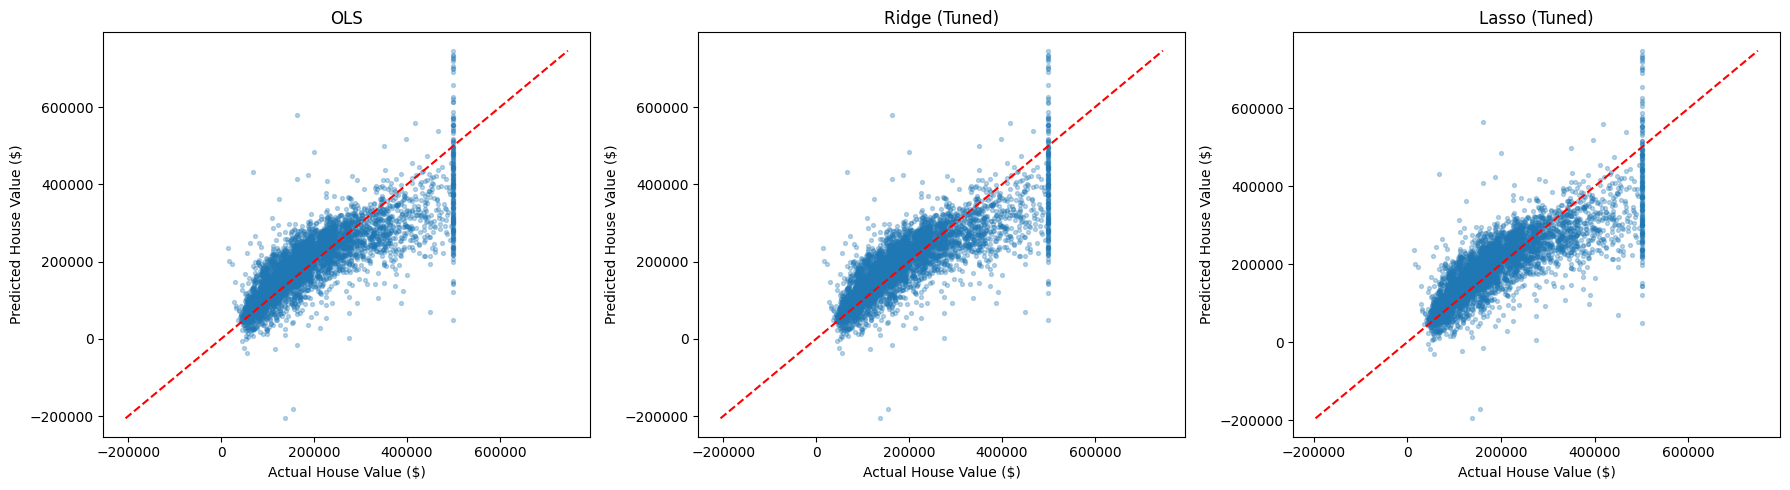

In [ ]:

# Actual vs. predicted house values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, final_predictions.items()):
    ax.scatter(y_test, predictions, alpha=0.3, s=8)

    lower = min(y_test.min(), predictions.min())
    upper = max(y_test.max(), predictions.max())
    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

plt.tight_layout()
plt.show()


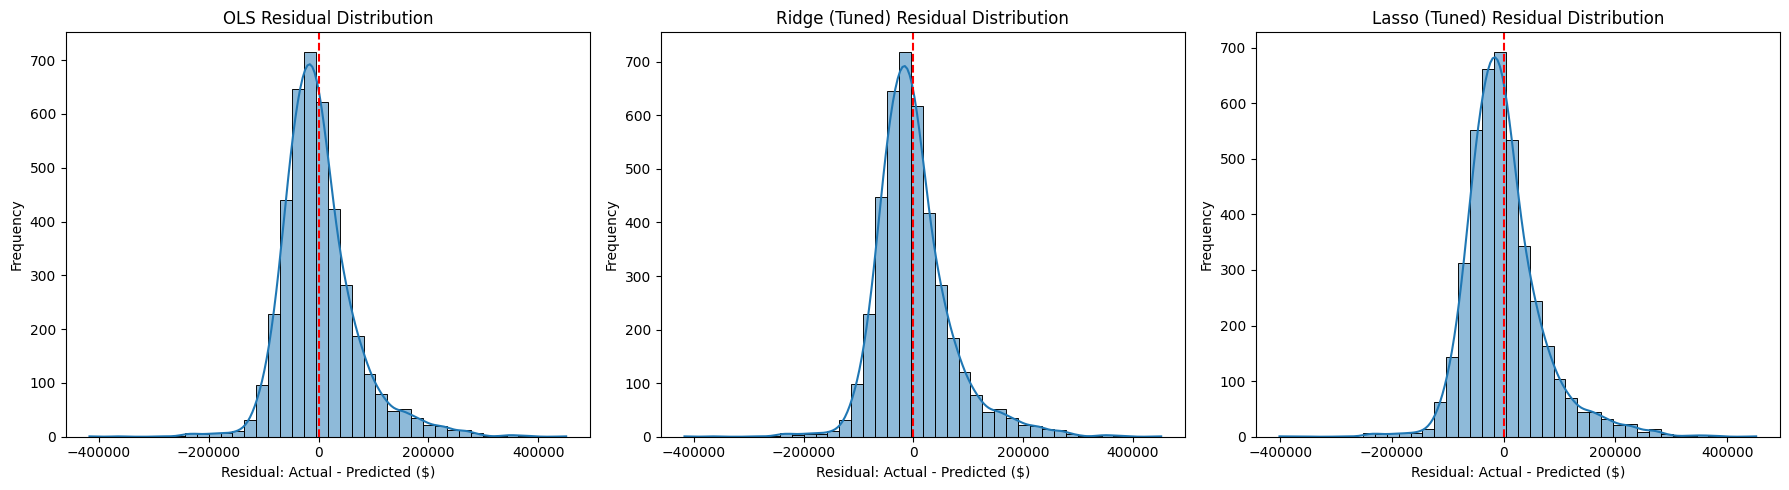

In [ ]:

# Residual distribution comparison

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, final_predictions.items()):
    residuals = y_test.to_numpy() - predictions

    sns.histplot(residuals, bins=40, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")

    ax.set_title(f"{name} Residual Distribution")
    ax.set_xlabel("Residual: Actual - Predicted ($)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 9. Residual Diagnostics

Residual diagnostics help identify systematic prediction errors, non-constant error variance, and possible model limitations. We examine residuals against predicted house values for each final model.

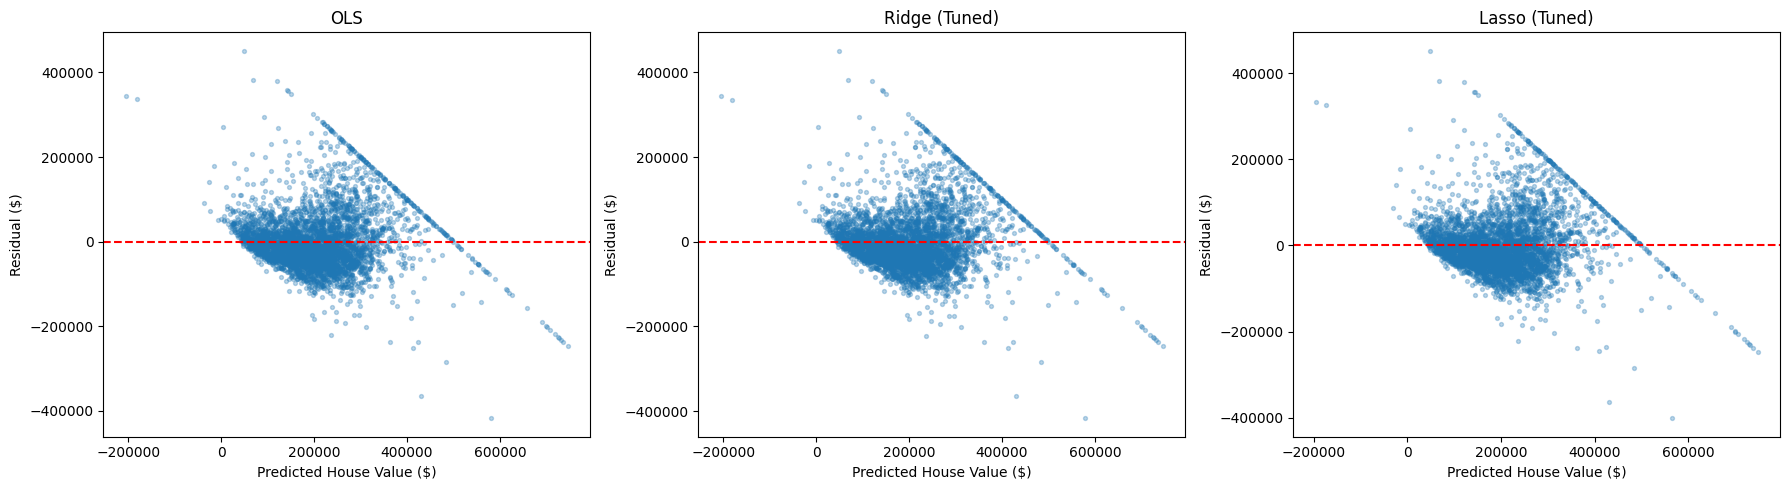

In [ ]:

# Step 9.1: Residuals versus predicted values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, final_predictions.items()):
    residuals = y_test.to_numpy() - predictions

    ax.scatter(predictions, residuals, alpha=0.3, s=8)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Predicted House Value ($)")
    ax.set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()


## 10. Multicollinearity Analysis Using VIF

Variance Inflation Factor (VIF) measures how strongly a numerical predictor can be explained by other predictors. High VIF values can indicate unstable regression coefficients. We calculate VIF for the numerical features after median imputation and standardization, using training data only.

In [ ]:

# Step 10.1: Calculate VIF for numerical predictors

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use numerical training features only
X_num_train = X_train[numeric_features].copy()

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_num_imputed = imputer.fit_transform(X_num_train)
X_num_scaled = scaler.fit_transform(X_num_imputed)

vif_df = pd.DataFrame({
    "Feature": numeric_features,
    "VIF": [
        variance_inflation_factor(X_num_scaled, i)
        for i in range(X_num_scaled.shape[1])
    ]
})

display(vif_df.sort_values("VIF", ascending=False).round(2))


,Feature,VIF
4,total_bedrooms,50.70
6,households,46.00
3,total_rooms,19.55
1,latitude,9.42
0,longitude,9.09
11,income_x_house_age,9.09
7,median_income,7.59
5,population,6.82
2,housing_median_age,5.44
9,bedrooms_per_room,2.81


## 11. Results and Conclusion

### Project Summary

This project developed and evaluated regression models to predict median house values using the California Housing dataset. The dataset contains 20,640 records and 10 original columns. Data preprocessing included median imputation, standardization of numerical features, one-hot encoding of categorical features, and feature engineering.

Four engineered features were added: rooms per household, bedrooms per room, population per household, and the interaction between median income and housing median age. The dataset was split into training and testing sets using an 80:20 ratio.

### Model Comparison

Three regression approaches were evaluated: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression. Ridge and Lasso hyperparameters were selected using five-fold GridSearchCV.

On the held-out test set:

- **OLS:** RMSE = 69,048.19, MAE = 49,376.49, R² = 0.6362.
- **Ridge:** RMSE = 69,056.22, MAE = 49,382.63, R² = 0.6361.
- **Lasso:** RMSE = 69,100.07, MAE = 49,369.60, R² = 0.6356.

OLS achieved the lowest test RMSE and the highest R² among the three evaluated models. Lasso achieved the lowest MAE. The performance differences were small, indicating that all three models provided broadly similar predictive performance.

### Multicollinearity Analysis

The correlation heatmap and Variance Inflation Factor (VIF) analysis identified substantial multicollinearity, particularly among total bedrooms, households, and total rooms. This can make individual regression coefficients less stable. Ridge and Lasso provide regularization, but the final comparison did not demonstrate a meaningful predictive advantage over OLS.

### Conclusion

The OLS model was the best-performing model by test RMSE in this experiment. Its test R² of approximately 0.636 indicates that it explained about 63.6% of the variation in median house values in the test set.

The residual plots also indicate that prediction errors remain, particularly for some expensive homes. Further work could explore nonlinear regression models, additional feature engineering, and separate analysis of the upper house-value range. All reported metrics represent performance on the held-out test set, and results may vary with different data splits.